# Will it ignite or go out? Predicting flammability in microgravity and partial gravity

**Equipo Dinamita · NASA Space Apps 2026 · Flame in Freefall**

Question: for a cabin material (PMMA, acrylic) at a given oxygen level, ventilation and gravity, does the flame sustain or go out?

Data (all public, cited in `data/flammability_data.json`):
- **Training**: 51 BASS-II tests on the ISS (0 g), PMMA rods. Olson & Ferkul, *Combust. Flame* 180 (2017), reproduced in NASA/TM-20210011385.
- **External validation**: 16 centrifuge tests at 0.04, 0.16, 0.38, 0.65 and 1 g (Olson et al., *Fire Safety J.* 2024). The model never sees them during training.
- **Reference**: the flammability boundary published by the authors (not used for training).

We answer five questions:
1. Probability that the flame sustains.
2. Minimum oxygen for ignition on the Moon and on Mars.
3. Most dangerous ventilation.
4. Whether cutting the ventilation puts the fire out.
5. Safety margin of each habitat.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, brentq
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, GroupKFold
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss, brier_score_loss, confusion_matrix
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)
HERE = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd() / "ml"
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})
BURN, EXT = "#e8743b", "#3b7de8"

raw = json.loads((HERE / "data" / "flammability_data.json").read_text())
series = {s["id"]: s for s in raw["series"] + raw["partial_gravity"]}

ug = pd.DataFrame(series["pmma_ug_bassII_rods"]["points"])
ug = ug[ug.outcome.isin(["burn", "extinct"])].assign(y=lambda d: (d.outcome == "burn").astype(int), g=0.0)
pg = pd.DataFrame(series["pmma_rod_centrifuge_partial_g"]["points"])
pg = pg[pg.outcome.isin(["burn", "extinct"])].assign(y=lambda d: (d.outcome == "burn").astype(int), flow_cm_s=0.0).rename(columns={"gravity_g": "g"})
ref = pd.DataFrame(series["pmma_ug_bassII_boundary_fit"]["points"])
print(f"Training (0 g): {len(ug)} tests | Validation (partial gravity): {len(pg)} tests")

Training (0 g): 51 tests | Validation (partial gravity): 16 tests


## 1. EDA

In [2]:
display_cols = ["flow_cm_s", "o2_pct", "y"]
print(ug[display_cols].describe().round(2))
print("\nClass balance (0 g):", ug.y.value_counts().rename({1: "burns", 0: "goes out"}).to_dict())
print("Class balance (partial gravity):", pg.y.value_counts().rename({1: "burns", 0: "goes out"}).to_dict())

       flow_cm_s  o2_pct      y
count      51.00   51.00  51.00
mean        6.18   15.00   0.53
std         7.68    0.99   0.50
min         0.24   13.51   0.00
25%         0.76   14.36   0.00
50%         2.32   14.81   1.00
75%         9.56   15.51   1.00
max        31.65   18.01   1.00

Class balance (0 g): {'burns': 27, 'goes out': 24}
Class balance (partial gravity): {'goes out': 9, 'burns': 7}


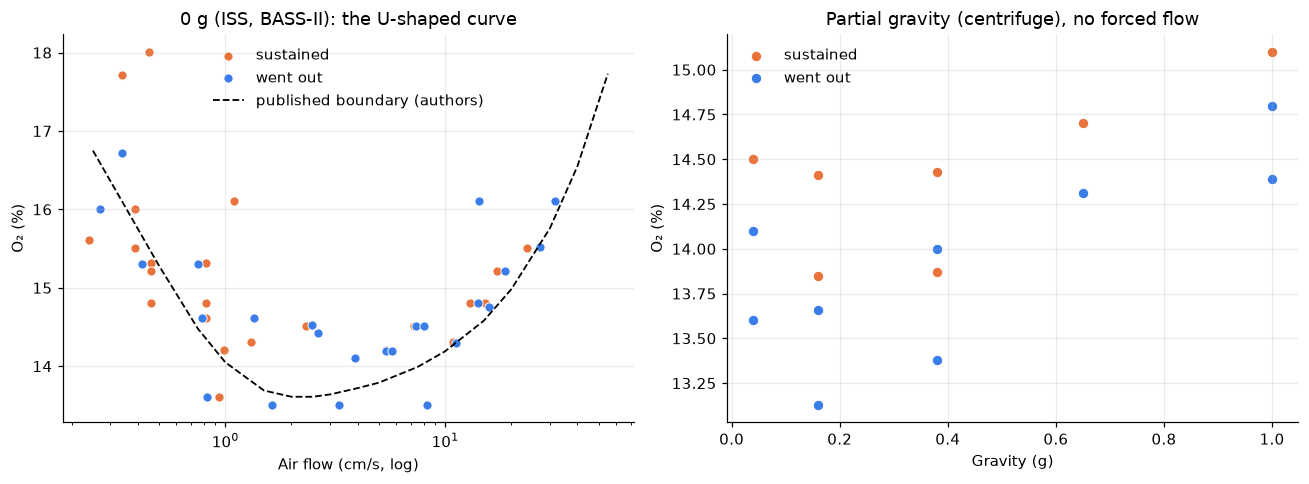

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for y, c, lab in [(1, BURN, "sustained"), (0, EXT, "went out")]:
    d = ug[ug.y == y]
    ax[0].scatter(d.flow_cm_s, d.o2_pct, c=c, label=lab, s=36, edgecolor="white", linewidth=0.6)
ax[0].plot(ref.flow_cm_s, ref.o2_pct, "k--", lw=1.2, label="published boundary (authors)")
ax[0].set(xscale="log", xlabel="Air flow (cm/s, log)", ylabel="O₂ (%)", title="0 g (ISS, BASS-II): the U-shaped curve")
ax[0].legend(frameon=False)
for y, c, lab in [(1, BURN, "sustained"), (0, EXT, "went out")]:
    d = pg[pg.y == y]
    ax[1].scatter(d.g, d.o2_pct, c=c, label=lab, s=46, edgecolor="white", linewidth=0.6)
ax[1].set(xlabel="Gravity (g)", ylabel="O₂ (%)", title="Partial gravity (centrifuge), no forced flow")
ax[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "eda_scatter.png", bbox_inches="tight"); plt.show()

**Reading the EDA**
- At low flow (< 1 cm/s) the flame needs **more** O₂, because it loses heat by radiation and starves. At high flow it also needs more, because the air blows it out. The minimum lies in between, near 2 cm/s, and this is **the most dangerous ventilation**.
- The two classes barely separate. Everything happens between 13.5 and 17 % O₂.
- **Experimental noise**: below we count pairs of tests at nearly identical conditions with opposite outcomes, and we measure how often NASA's own curve is right.

**Main takeaway from the EDA.** The tests were run on purpose *at the edge* (within 1 point of O₂ from the boundary), because that is how a boundary is measured. There the outcome is close to a coin flip, and even the curve published by NASA does only a little better than chance. **Individual tests near the boundary cannot be predicted, but the location of the boundary can**, and that is what matters for a habitat that will sit many points above it.

In [4]:
ug_sorted = ug.sort_values(["flow_cm_s", "o2_pct"]).reset_index(drop=True)
conflicts = [(a.flow_cm_s, a.o2_pct) for (_, a), (_, b) in zip(ug_sorted.iterrows(), ug_sorted.iloc[1:].iterrows())
             if abs(np.log(a.flow_cm_s / b.flow_cm_s)) < 0.08 and abs(a.o2_pct - b.o2_pct) < 0.15 and a.y != b.y]
print(f"Nearly identical pairs with opposite outcome: {len(conflicts)} → {conflicts}")

L_nasa = np.interp(np.log(ug.flow_cm_s), np.log(ref.flow_cm_s), ref.o2_pct)
acc_nasa = float(((ug.o2_pct > L_nasa) == ug.y).mean())
bins = pd.qcut(np.log(ug.flow_cm_s), 6, labels=False)
ceiling = sum(max(((d.o2_pct > t) == d.y).sum() for t in np.r_[d.o2_pct - 1e-3, d.o2_pct + 1e-3]) for _, d in ug.groupby(bins)) / len(ug)
print(f"Accuracy of the NASA published curve on these tests: {acc_nasa:.0%}")
print(f"Optimistic ceiling (ideal threshold per flow range, same sample): {ceiling:.0%}")
print(f"Distance of each test to the NASA boundary: mean {np.mean(np.abs(ug.o2_pct - L_nasa)):.2f} O₂ points")

Nearly identical pairs with opposite outcome: 11 → [(0.34, 16.72), (0.78, 14.61), (1.35, 14.61), (2.32, 14.51), (5.41, 14.2), (5.41, 14.21), (7.2, 14.51), (7.98, 14.51), (10.84, 14.31), (14.26, 16.11), (15.22, 14.81)]
Accuracy of the NASA published curve on these tests: 55%
Optimistic ceiling (ideal threshold per flow range, same sample): 71%
Distance of each test to the NASA boundary: mean 0.58 O₂ points


## 2. Models

Since the EDA showed that each individual test is noisy, we split the problem in two parts.

**a) Where the boundary lies in 0 g.** We use the physical form
$$L(u) = A + \frac{B}{u} + C\,u$$
where $B/u$ is radiative extinction at low flow and $C\,u$ is blowoff at high flow. We fit $A, B, C$ to the boundary curve published by NASA, which already combines all their tests and corrects for the O₂ drop during each burn.

**b) How it changes with gravity (our contribution).** Buoyancy moves the air on its own. We model it as an extra flow:
$$u_\text{eff} = \sqrt{u_\text{ventilation}^2 + (U_b\, g^{\,n})^2}$$
with $U_b = 20$ cm/s at 1 g (value from the authors) and an exponent $n$ that we calibrate **leaving out one gravity level at a time**. The probability that the flame sustains is
$$P = \sigma\!\left(\frac{O_2 - L(u_\text{eff})}{s}\right)$$
with $s$ estimated by maximum likelihood on the 51 tests.

**ML models for comparison** (trained on the 51 tests at 0 g):
- Logistic regression with $(O_2,\ 1/u,\ u)$.
- XGBoost with $(O_2,\ u_\text{ventilation})$: the course model, without physics.
- Hybrid XGBoost with $(O_2,\ u_\text{eff})$: the same XGBoost, with the physical variable.

In [5]:
UB = 20.0
X_ref = np.c_[np.ones(len(ref)), 1 / ref.flow_cm_s, ref.flow_cm_s]
ABC, *_ = np.linalg.lstsq(X_ref, ref.o2_pct.values, rcond=None)
curve_err = np.abs(X_ref @ ABC - ref.o2_pct.values)
print(f"A = {ABC[0]:.3f}, B = {ABC[1]:.3f}, C = {ABC[2]:.4f} | max. error against the NASA curve: {curve_err.max():.2f} pts")
U_STAR = float(np.sqrt(ABC[1] / ABC[2]))
print(f"Most dangerous flow in 0 g: {U_STAR:.1f} cm/s (limiting O₂ {ABC[0] + 2 * np.sqrt(ABC[1] * ABC[2]):.2f} %)")

def u_eff(flow, g, n, ub=UB):
    return np.sqrt(np.asarray(flow, float) ** 2 + (ub * np.asarray(g, float) ** n) ** 2).clip(0.05)

def limit(u, abc=ABC, shift=0.0):
    return abc[0] + abc[1] / u + abc[2] * u + shift

S_NOISE = float(minimize(lambda t: log_loss(ug.y, np.clip(1 / (1 + np.exp(-(ug.o2_pct - limit(ug.flow_cm_s.clip(0.05))) / t[0])), 1e-4, 1 - 1e-4)) if t[0] > 0.05 else 9, [0.5], method="Nelder-Mead").x[0])
print(f"Per-test noise width s = {S_NOISE:.2f} O₂ points")

def p_burn(o2, u, shift=0.0, s=None):
    return 1 / (1 + np.exp(-(np.asarray(o2, float) - limit(u, shift=shift)) / (s or S_NOISE)))

def feats_logit(df):
    u = df.flow_cm_s.clip(0.05).values
    return np.c_[df.o2_pct, 1 / u, u]

def xgb():
    return XGBClassifier(n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.9, reg_lambda=2.0, random_state=SEED, verbosity=0)

A = 13.145, B = 0.913, C = 0.0848 | max. error against the NASA curve: 0.27 pts
Most dangerous flow in 0 g: 3.3 cm/s (limiting O₂ 13.70 %)
Per-test noise width s = 2.27 O₂ points


### Validation in 0 g (classifying individual tests)
Two schemes: **repeated stratified k-fold** and **by flow blocks** (a whole range of flows is left out). These results should be read against the EDA references, the NASA curve and the noise ceiling.

In [6]:
def evaluate(splitter, groups=None):
    rows = {k: {"y": [], "p": []} for k in ["Physics (NASA curve)", "Logistic", "XGBoost"]}
    split = splitter.split(ug, ug.y, groups) if groups is not None else splitter.split(ug, ug.y)
    for tr, te in split:
        a, b = ug.iloc[tr], ug.iloc[te]
        rows["Physics (NASA curve)"]["p"] += list(p_burn(b.o2_pct, b.flow_cm_s.clip(0.05)))
        lr = LogisticRegression(C=10, max_iter=2000).fit(feats_logit(a), a.y)
        rows["Logistic"]["p"] += list(lr.predict_proba(feats_logit(b))[:, 1])
        m = xgb().fit(a[["o2_pct", "flow_cm_s"]], a.y)
        rows["XGBoost"]["p"] += list(m.predict_proba(b[["o2_pct", "flow_cm_s"]])[:, 1])
        for r in rows.values():
            r["y"] += list(b.y)
    return pd.DataFrame({k: {"accuracy": accuracy_score(v["y"], np.array(v["p"]) > 0.5), "AUC": roc_auc_score(v["y"], v["p"]),
                             "log-loss": log_loss(v["y"], np.clip(v["p"], 1e-4, 1 - 1e-4)), "Brier": brier_score_loss(v["y"], v["p"])}
                         for k, v in rows.items()}).T.round(3)

cv_interp = evaluate(RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED))
blocks = pd.qcut(np.log(ug.flow_cm_s), 5, labels=False).values
cv_block = evaluate(GroupKFold(n_splits=5), groups=blocks)
print("Stratified k-fold ×10\n", cv_interp, "\n\nBy flow blocks\n", cv_block)
print(f"\nReferences: NASA curve {acc_nasa:.3f} | optimistic ceiling {ceiling:.3f} | chance ~0.53")

Stratified k-fold ×10
                       accuracy    AUC  log-loss  Brier
Physics (NASA curve)     0.569  0.581     0.678  0.243
Logistic                 0.569  0.584     0.715  0.256
XGBoost                  0.431  0.470     0.854  0.317 

By flow blocks
                       accuracy    AUC  log-loss  Brier
Physics (NASA curve)     0.569  0.581     0.678  0.243
Logistic                 0.549  0.626     0.706  0.250
XGBoost                  0.569  0.557     0.739  0.266

References: NASA curve 0.549 | optimistic ceiling 0.706 | chance ~0.53


**Reading.** No model goes much beyond 55-60 %. This reflects the noise of tests run at the edge, and is not a flaw of the models. XGBoost falls **below chance** in k-fold, because it memorizes the "twin" test with the opposite outcome that remained in the training set. This is textbook overfitting.

### External validation: partial gravity (the test that matters)
The 16 centrifuge tests come from **a different lab, a different year and different gravity levels**, and no model sees them during training. We measure two things.
- **Boundary**: at each gravity level, the midpoint between the last test that went out and the first one that sustained, compared with the predicted boundary.
- **Classification** of each test.

In [7]:
def observed_limits(df):
    out = []
    for gl, d in df.groupby("g"):
        out.append((gl, (d[d.y == 0].o2_pct.max() + d[d.y == 1].o2_pct.min()) / 2))
    return pd.DataFrame(out, columns=["g", "observed"])

obs = observed_limits(pg)
grid_n = np.round(np.arange(0.2, 2.01, 0.05), 2)
def mae_n(n, rows):
    return float(np.mean(np.abs(limit(u_eff(0, rows.g, n)) - rows.observed)))

chosen = {}
loo_limit = {}
for gl in obs.g:
    train = obs[obs.g != gl]
    chosen[gl] = float(min(grid_n, key=lambda n: mae_n(n, train)))
    loo_limit[gl] = float(limit(u_eff(0, gl, chosen[gl])))
N_EXP = float(np.median(list(chosen.values())))
obs = obs.assign(theory_n_one_third=limit(u_eff(0, obs.g, 1 / 3)), calibrated_loo=obs.g.map(loo_limit))
mae_theory = float(np.mean(np.abs(obs.theory_n_one_third - obs.observed)))
mae_loo = float(np.mean(np.abs(obs.calibrated_loo - obs.observed)))
print("n chosen in each fold:", chosen, "→ n =", N_EXP)
print(obs.round(2))
print(f"\nMean boundary error: simple theory (n = 1/3) {mae_theory:.2f} pts | calibrated leave-one-g-out {mae_loo:.2f} pts")

loo_p = np.array([p_burn(o2, u_eff(0, g, chosen[g])) for o2, g in zip(pg.o2_pct, pg.g)])
ext = {
    "Physics, calibrated n (leave-one-g-out)": loo_p,
    "Physics, simple theory n = 1/3": p_burn(pg.o2_pct, u_eff(0, pg.g, 1 / 3)),
    "XGBoost hybrid (O₂, u_eff)": xgb().fit(np.c_[ug.o2_pct, ug.flow_cm_s], ug.y).predict_proba(np.c_[pg.o2_pct, u_eff(0, pg.g, N_EXP)])[:, 1],
    "XGBoost without physics (O₂, ventilation)": xgb().fit(ug[["o2_pct", "flow_cm_s"]], ug.y).predict_proba(pg[["o2_pct", "flow_cm_s"]])[:, 1],
    "Logistic without gravity": LogisticRegression(C=10, max_iter=2000).fit(feats_logit(ug), ug.y).predict_proba(feats_logit(pg))[:, 1],
    "Always 'goes out' (majority class)": np.full(len(pg), 0.001),
}
ext_tbl = pd.DataFrame({k: {"accuracy": accuracy_score(pg.y, v > 0.5), "log-loss": log_loss(pg.y, np.clip(v, 1e-4, 1 - 1e-4)), "Brier": brier_score_loss(pg.y, v)} for k, v in ext.items()}).T.round(3)
print(ext_tbl)
print("\nConfusion matrix, calibrated physics (rows: actual goes out/burns):\n", confusion_matrix(pg.y, loo_p > 0.5))
one_g = [(l["o2_pct"], l["test"][:60]) for l in raw["one_g_limits"] if "PMMA" in l["material"]]
print(f"\nIndependent check at 1 g: the model predicts {float(limit(u_eff(0, 1.0, N_EXP))):.2f} % | literature: {one_g}")

n chosen in each fold: {0.04: 0.75, 0.16: 1.0, 0.38: 1.0, 0.65: 1.0, 1.0: 1.0} → n = 1.0
      g  observed  theory_n_one_third  calibrated_loo
0  0.04     14.30               13.86           13.81
1  0.16     13.76               14.15           13.70
2  0.38     13.93               14.44           13.91
3  0.65     14.50               14.67           14.32
4  1.00     14.95               14.89           14.89

Mean boundary error: simple theory (n = 1/3) 0.31 pts | calibrated leave-one-g-out 0.16 pts


                                           accuracy  log-loss  Brier
Physics, calibrated n (leave-one-g-out)       0.812     0.639  0.223
Physics, simple theory n = 1/3                0.750     0.641  0.224
XGBoost hybrid (O₂, u_eff)                    0.625     0.684  0.230
XGBoost without physics (O₂, ventilation)     0.688     0.626  0.217
Logistic without gravity                      0.562     1.072  0.359
Always 'goes out' (majority class)            0.562     3.023  0.437

Confusion matrix, calibrated physics (rows: actual goes out/burns):
 [[7 2]
 [1 6]]

Independent check at 1 g: the model predicts 14.89 % | literature: [(15.4, 'upward flame spread limit, normal gravity, with additional 4'), (15.0, 'upward burning limit, minimum over flow (min at 12 cm/s O2/N'), (18.4, 'downward burning limit, ~independent of flow 5-40 cm/s'), (13.4, '1g blowoff boundary linearly extrapolated to zero stretch (p')]


**Reading.**
- With no calibration at all, the physics already predicts the partial-gravity boundary with ~0.3 points of error. Calibrating a single number ($n$) with honest validation (each gravity level is predicted without having been used), the error drops to ~0.16 points and 13 of 16 tests are classified correctly.
- The best exponent is $n \approx 1$, so the flow induced by gravity grows **linearly** with $g$. This fits small flames at low gravity, where viscosity dominates (low Grashof number).
- XGBoost has no notion of gravity. Even when given the physical variable $u_\text{eff}$ it does not improve, because with 51 noisy tests the trees learn the noise and not the shape of the curve. **With little data, a model with the physics built in and 4 parameters beats a flexible model.** This is the most useful lesson of the notebook.

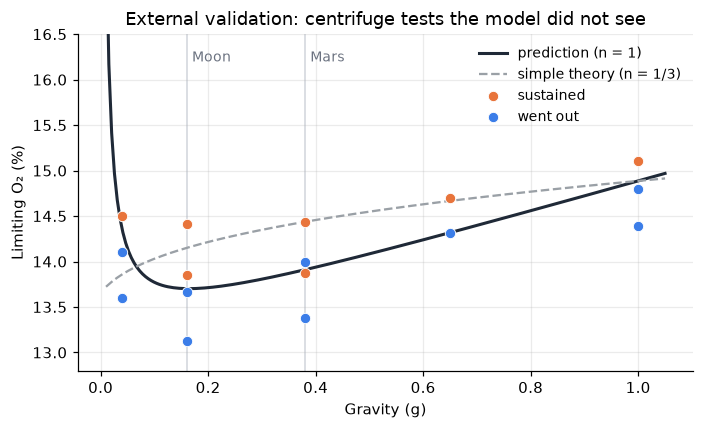

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4))
gg = np.linspace(0.01, 1.05, 200)
ax.plot(gg, limit(u_eff(0, gg, N_EXP)), color="#1f2937", lw=2, label=f"prediction (n = {N_EXP:g})")
ax.plot(gg, limit(u_eff(0, gg, 1 / 3)), color="#9aa0a6", lw=1.5, ls="--", label="simple theory (n = 1/3)")
for y, c, lab in [(1, BURN, "sustained"), (0, EXT, "went out")]:
    d = pg[pg.y == y]
    ax.scatter(d.g, d.o2_pct, c=c, s=46, edgecolor="white", linewidth=0.6, label=lab, zorder=3)
for gl, name in [(0.16, "Moon"), (0.38, "Mars")]:
    ax.axvline(gl, color="#d1d5db", lw=1, zorder=0); ax.text(gl + 0.01, 16.2, name, fontsize=9, color="#6b7280")
ax.set(ylim=(12.8, 16.5), xlabel="Gravity (g)", ylabel="Limiting O₂ (%)", title="External validation: centrifuge tests the model did not see")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "validation_gravity.png", bbox_inches="tight"); plt.show()

### Uncertainty (Monte Carlo, 2000 samples)
We combine three sources: the exponent $n$ (from the folds), the buoyant flow at 1 g ($U_b$ between 15 and 25 cm/s) and a shift of the curve with standard deviation equal to the mean validation error.

In [9]:
MC = 2000
mc_n = rng.choice(list(chosen.values()), MC) + rng.normal(0, 0.05, MC)
mc_ub = rng.uniform(15, 25, MC)
mc_shift = rng.normal(0, max(mae_loo, 0.15), MC)

def mc(f):
    vals = np.array([f(n, ub, sh) for n, ub, sh in zip(mc_n, mc_ub, mc_shift)])
    return float(f(N_EXP, UB, 0.0)), float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

## 3. The five predictions

In [10]:
GRAV = {"0 g (ISS)": 0.0, "Moon (0.16 g)": 0.16, "Mars (0.38 g)": 0.38, "Earth (1 g)": 1.0}
SCEN = {"iss": ("ISS / Orion", 21, 10, 0.0), "rover": ("Lunar rover", 30, 5, 0.16), "moonbase": ("Lunar base", 34, 5, 0.16),
        "mars": ("Mars habitat", 34, 5, 0.38)}
flows = np.r_[0.0, np.geomspace(0.05, 60, 400)]
RESIDUAL = 0.1

pred = {"model": {"A": ABC[0], "B": ABC[1], "C": ABC[2], "s": S_NOISE, "Ub": UB, "n": N_EXP, "u_star": U_STAR,
                  "mc": np.c_[mc_n[:300], mc_ub[:300], mc_shift[:300]].round(4).tolist()}, "gravity": {}, "habitats": {}}
for name, g in GRAV.items():
    loc = mc(lambda n, ub, sh: limit(u_eff(flows, g, n, ub), shift=sh).min())
    natural = mc(lambda n, ub, sh: float(ub * g ** n))
    worst = mc(lambda n, ub, sh: float(flows[limit(u_eff(flows, g, n, ub), shift=sh).argmin()]))
    cut = mc(lambda n, ub, sh: float(limit(u_eff(RESIDUAL, g, n, ub), shift=sh)))
    pred["gravity"][name] = {"g": g, "loc": loc, "natural_flow": natural, "worst_vent": worst, "limit_vent_cut": cut}
    print(f"{name:15s} | minimum O₂: {loc[0]:.2f} % (CI {loc[1]:.2f}–{loc[2]:.2f}) | flow induced by gravity: {natural[0]:.1f} cm/s "
          f"| most dangerous ventilation: {worst[0]:.1f} cm/s | boundary with ventilation cut: {cut[0]:.1f} % (CI {cut[1]:.1f}–{cut[2]:.1f})")

0 g (ISS)       | minimum O₂: 13.70 % (CI 13.38–14.03) | flow induced by gravity: 0.0 cm/s | most dangerous ventilation: 3.3 cm/s | boundary with ventilation cut: 22.3 % (CI 22.0–22.6)
Moon (0.16 g)   | minimum O₂: 13.70 % (CI 13.40–14.05) | flow induced by gravity: 3.2 cm/s | most dangerous ventilation: 0.7 cm/s | boundary with ventilation cut: 13.7 % (CI 13.4–14.1)
Mars (0.38 g)   | minimum O₂: 13.91 % (CI 13.56–14.35) | flow induced by gravity: 7.6 cm/s | most dangerous ventilation: 0.0 cm/s | boundary with ventilation cut: 13.9 % (CI 13.6–14.4)


Earth (1 g)     | minimum O₂: 14.89 % (CI 14.33–15.44) | flow induced by gravity: 20.0 cm/s | most dangerous ventilation: 0.0 cm/s | boundary with ventilation cut: 14.9 % (CI 14.3–15.4)


In [11]:
for key, (label, o2, flow, g) in SCEN.items():
    pb = mc(lambda n, ub, sh: float(p_burn(o2, u_eff(flow, g, n, ub), sh)))
    margin = mc(lambda n, ub, sh: o2 - float(limit(u_eff(flow, g, n, ub), shift=sh)))
    p_cut = mc(lambda n, ub, sh: float(p_burn(o2, u_eff(RESIDUAL, g, n, ub), sh)))
    pred["habitats"][key] = {"label": label, "o2": o2, "flow": flow, "g": g, "p_burn": pb, "margin": margin, "p_burn_vent_cut": p_cut}
    print(f"{label:17s} O₂ {o2}% | P(sustains) = {pb[0]:.3f} | margin: {margin[0]:+.1f} pts (CI {margin[1]:+.1f} to {margin[2]:+.1f}) "
          f"| with ventilation cut: P = {p_cut[0]:.3f}")

ISS / Orion       O₂ 21% | P(sustains) = 0.955 | margin: +6.9 pts (CI +6.6 to +7.2) | with ventilation cut: P = 0.362
Lunar rover       O₂ 30% | P(sustains) = 0.999 | margin: +16.2 pts (CI +15.8 to +16.5) | with ventilation cut: P = 0.999
Lunar base        O₂ 34% | P(sustains) = 1.000 | margin: +20.2 pts (CI +19.8 to +20.5) | with ventilation cut: P = 1.000


Mars habitat      O₂ 34% | P(sustains) = 1.000 | margin: +20.0 pts (CI +19.6 to +20.3) | with ventilation cut: P = 1.000


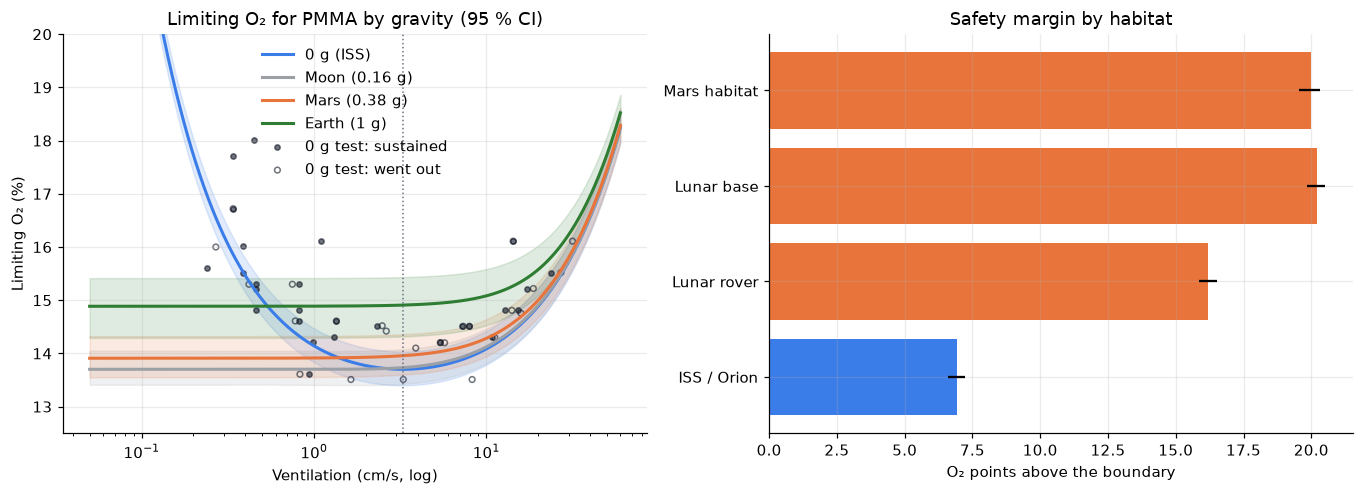

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))
for (name, g), c in zip(GRAV.items(), ["#3b7de8", "#9aa0a6", "#e8743b", "#2e7d32"]):
    band = np.array([limit(u_eff(flows[1:], g, n, ub), shift=sh) for n, ub, sh in zip(mc_n[:400], mc_ub[:400], mc_shift[:400])])
    ax[0].fill_between(flows[1:], *np.percentile(band, [2.5, 97.5], axis=0), color=c, alpha=0.15)
    ax[0].plot(flows[1:], limit(u_eff(flows[1:], g, N_EXP)), color=c, lw=2, label=name)
ax[0].scatter(ug.flow_cm_s[ug.y == 1], ug.o2_pct[ug.y == 1], c="#111827", s=12, alpha=0.6, label="0 g test: sustained")
ax[0].scatter(ug.flow_cm_s[ug.y == 0], ug.o2_pct[ug.y == 0], facecolors="none", edgecolors="#111827", s=14, alpha=0.6, label="0 g test: went out")
ax[0].axvline(U_STAR, color="#6b7280", lw=1, ls=":")
ax[0].set(xscale="log", ylim=(12.5, 20), xlabel="Ventilation (cm/s, log)", ylabel="Limiting O₂ (%)", title="Limiting O₂ for PMMA by gravity (95 % CI)")
ax[0].legend(frameon=False)
labels = [v["label"] for v in pred["habitats"].values()]
m = np.array([v["margin"] for v in pred["habitats"].values()])
ax[1].barh(labels, m[:, 0], xerr=[m[:, 0] - m[:, 1], m[:, 2] - m[:, 0]], color=["#3b7de8" if x < 10 else "#e8743b" for x in m[:, 0]])
ax[1].axvline(0, color="k", lw=1)
ax[1].set(xlabel="O₂ points above the boundary", title="Safety margin by habitat")
fig.tight_layout(); fig.savefig(FIG / "predictions.png", bbox_inches="tight"); plt.show()

**What the predictions say**
1. **Probability**: in all Artemis habitats, a material like PMMA that ignites keeps burning (P ≈ 1).
2. **Minimum O₂**: on the Moon and on Mars it is around 13.6-13.9 %, equal to or **lower** than on the ISS. The planned atmospheres (30-34 %) are well above it.
3. **Most dangerous ventilation**: in 0 g, ~3.3 cm/s. On the Moon, gravity alone moves the air at ~3 cm/s, so **the lunar base sits right at the most dangerous point of the curve**.
4. **Cutting the ventilation**: on the ISS, if the air becomes nearly still, the boundary rises above 21 % and the flame starves. On the Moon and Mars it does not, because gravity keeps moving the air and the boundary barely changes.
5. **Margin**: +7 points on the ISS, +16 in the rover and ~+20 in the lunar base and on Mars. O₂ cannot be lowered to a non-flammable level without asphyxiating the crew, so safety depends on **material selection, early detection and suppression**.

**Limitations.** A single material (PMMA rods). Data at ~1 atm. At 8.2 psi materials tend to burn somewhat less, so the prediction errs on the safe side. Outside 13-18 % O₂ the model extrapolates with physics and not with data.

## 4. Feature importance (hybrid XGBoost) and extrapolation

In [13]:
mh = xgb().fit(pd.DataFrame({"O2": ug.o2_pct, "u_eff": ug.flow_cm_s}), ug.y)
print(pd.Series(mh.get_booster().get_score(importance_type="gain")).sort_values().round(2))
xg = xgb().fit(ug[["o2_pct", "flow_cm_s"]], ug.y)
for o2 in [18, 21, 25, 30, 34, 40]:
    print(f"O₂ {o2:>2}% in still air (0.1 cm/s) → XGBoost: {xg.predict_proba([[o2, 0.1]])[0, 1]:.2f} | physics: {p_burn(o2, 0.1):.2f}")

O2       0.54
u_eff    0.60
dtype: float64


O₂ 18% in still air (0.1 cm/s) → XGBoost: 0.64 | physics: 0.13
O₂ 21% in still air (0.1 cm/s) → XGBoost: 0.64 | physics: 0.36
O₂ 25% in still air (0.1 cm/s) → XGBoost: 0.64 | physics: 0.77
O₂ 30% in still air (0.1 cm/s) → XGBoost: 0.64 | physics: 0.97
O₂ 34% in still air (0.1 cm/s) → XGBoost: 0.64 | physics: 0.99
O₂ 40% in still air (0.1 cm/s) → XGBoost: 0.64 | physics: 1.00


All training data lie between 13 and 18 % O₂. At 34 %, XGBoost repeats the last value it saw, while the physics extends the trend. No material test has been run there, and **this is the data gap that the atlas shows**.

In [14]:
pred["validation"] = {"cv_interp": cv_interp.reset_index().rename(columns={"index": "model"}).to_dict("records"),
                      "cv_block": cv_block.reset_index().rename(columns={"index": "model"}).to_dict("records"),
                      "external": ext_tbl.reset_index().rename(columns={"index": "model"}).to_dict("records"),
                      "n_train": int(len(ug)), "n_external": int(len(pg)), "noise_pairs": len(conflicts),
                      "acc_nasa_curve": acc_nasa, "noise_ceiling": ceiling, "curve_max_err": float(curve_err.max()),
                      "mae_theory": mae_theory, "mae_loo": mae_loo, "n_by_fold": {str(k): v for k, v in chosen.items()},
                      "boundary_by_g": obs.round(3).to_dict("records"),
                      "pg_points": pg[["g", "o2_pct", "y"]].to_dict("records")}
pred["sources"] = ["Olson S.L., Ferkul P.V., Combust. Flame 180 (2017) 217-229; NASA/TM-20210011385 (BASS-II)",
                   "Olson S.L. et al., Fire Safety Journal (2024): partial-gravity centrifuge tests"]
out = HERE.parent / "lib" / "predictions.json"
out.write_text(json.dumps(pred, ensure_ascii=False, indent=1, default=float))
print("Exported to", out)

Exported to /Users/oletini/Proyectos/flame-in-freefall/lib/predictions.json
